## 1. Importación de librerías

Se cargan las librerías del ecosistema PyData utilizadas en el análisis: manipulación de datos (`numpy`, `pandas`), visualización (`matplotlib`, `seaborn`), estadística (`scipy`) y modelado (`scikit-learn`). También se importa la ruta base de datos crudos definida en la configuración del proyecto.

In [1]:
# Librerías PyData
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import sklearn

from ejercicio_clases.config import RAW_DATA_DIR

2026-10-27 20:38:31.755 | INFO     | ejercicio_clases.config:<module>:11 - PROJ_ROOT path is: C:\Users\aillu\OneDrive - Empresa Eléctrica de Guatemala, S.A. (EEGSA)\Mis Documentos\Universidad\4. Trimestre\1 - PRODUCT DEVELOPMENT\3. Semana\Ejercicio en Clases\ejercicio_clases


## 2. Carga de datos

Se cargan los conjuntos de entrenamiento y prueba. Las rutas se definen como parámetros para que puedan ajustarse si cambia la ubicación de las fuentes; actualmente apuntan a `data/raw/`.

In [2]:
# Rutas de las fuentes de información (cambiar aquí si los datos se mueven)
DATA_PATH = RAW_DATA_DIR
TRAIN_FILE = DATA_PATH / "train.csv"
TEST_FILE = DATA_PATH / "test.csv"

df_train = pd.read_csv(TRAIN_FILE)
df_test = pd.read_csv(TEST_FILE)

print(f"Train: {df_train.shape}")
print(f"Test:  {df_test.shape}")
df_train.head()

Train: (1460, 81)
Test:  (1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 3. Análisis de la variable objetivo: `SalePrice`

Se calculan las estadísticas descriptivas, la asimetría y la curtosis de `SalePrice`, y se grafica su función de densidad para evaluar la forma de la distribución.

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64
Asimetría (skewness): 1.8829
Curtosis: 6.5363


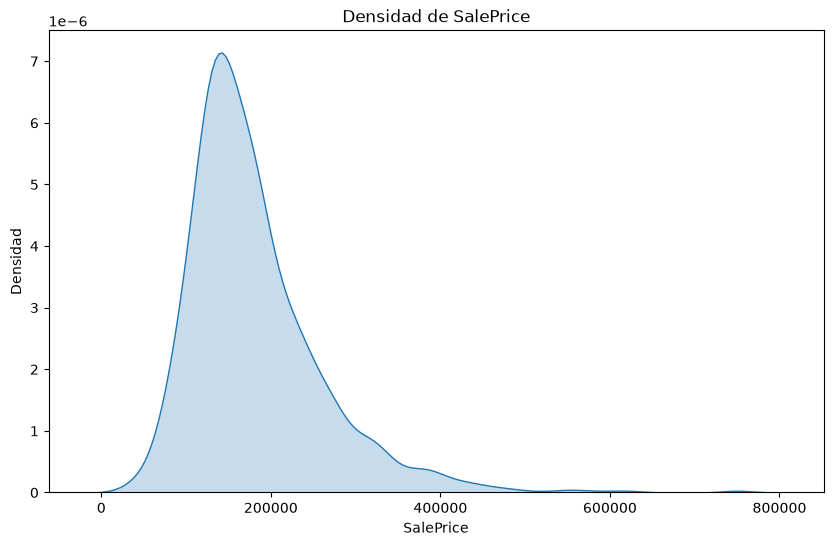

In [3]:
# Análisis de la variable target
TARGET = "SalePrice"

print(df_train[TARGET].describe())
print(f"Asimetría (skewness): {df_train[TARGET].skew():.4f}")
print(f"Curtosis: {df_train[TARGET].kurt():.4f}")

plt.figure(figsize=(10, 6))
sns.kdeplot(df_train[TARGET], fill=True)
plt.title(f"Densidad de {TARGET}")
plt.xlabel(TARGET)
plt.ylabel("Densidad")
plt.show()

## 4. Distribución de `SalePrice` — versión ejecutiva

Gráfica de densidad preparada para presentación a alta gerencia. Destaca el rango donde se concentra el 50 % central de las ventas (entre el percentil 25 y 75), la mediana y el promedio. La figura se exporta en alta resolución a `reports/figures/`.

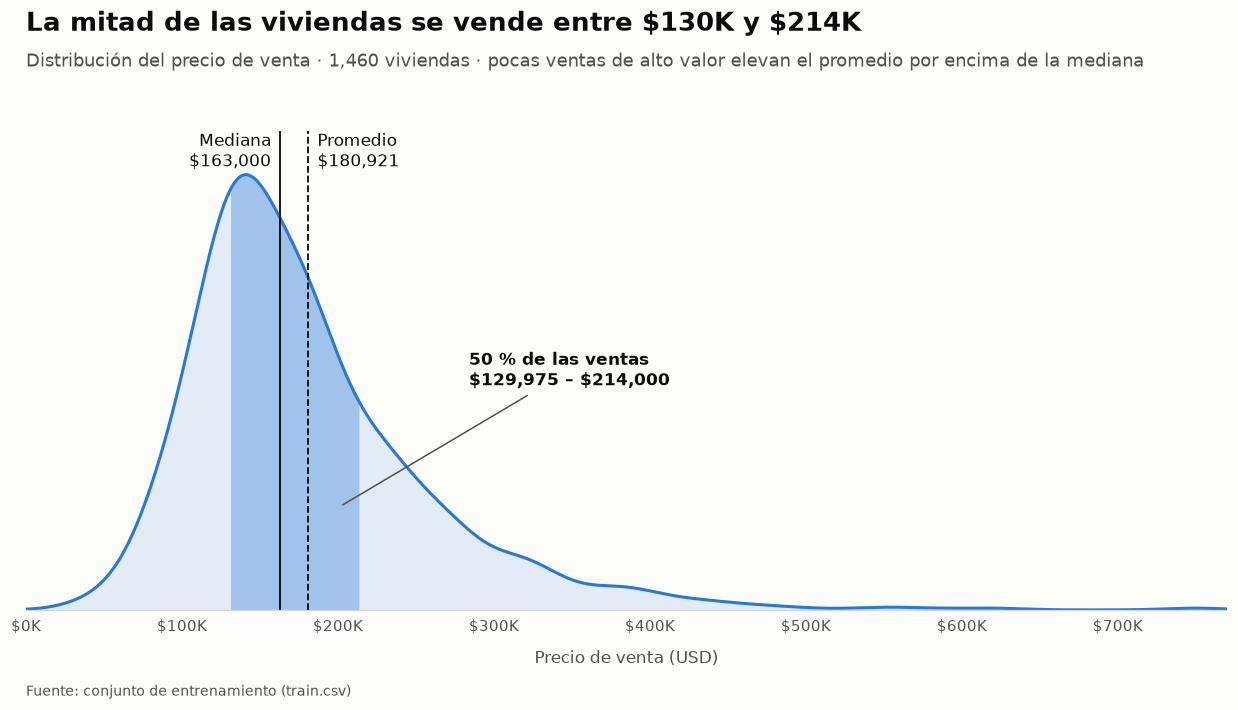

In [4]:
from matplotlib.ticker import FuncFormatter
from ejercicio_clases.config import FIGURES_DIR

# Paleta y tipografía
COLOR_SERIE = "#2a78d6"
TEXTO_PRIMARIO = "#0b0b0b"
TEXTO_SECUNDARIO = "#52514e"
FONDO = "#fcfcfb"

def usd(valor):
    # "\$" evita que matplotlib interprete el signo de dólar como fórmula matemática
    return f"\\${valor:,.0f}"


precios = df_train[TARGET].dropna()
p25, mediana, p75 = precios.quantile([0.25, 0.50, 0.75])
promedio = precios.mean()

# Curva de densidad
kde = stats.gaussian_kde(precios)
x = np.linspace(0, precios.max() * 1.02, 600)
y = kde(x)

fig, ax = plt.subplots(figsize=(12, 6.5), dpi=110)
fig.patch.set_facecolor(FONDO)
ax.set_facecolor(FONDO)

ax.fill_between(x, y, color=COLOR_SERIE, alpha=0.12, linewidth=0)
rango = (x >= p25) & (x <= p75)
ax.fill_between(x[rango], y[rango], color=COLOR_SERIE, alpha=0.35, linewidth=0)
ax.plot(x, y, color=COLOR_SERIE, linewidth=2)

# Líneas de referencia: mediana y promedio (etiquetas sobre el pico de la curva)
y_max = y.max()
altura_etiqueta = y_max * 1.10
for valor, etiqueta, estilo, ha, desplazamiento in [
    (mediana, "Mediana", "-", "right", -6),
    (promedio, "Promedio", "--", "left", 6),
]:
    ax.vlines(valor, 0, altura_etiqueta, color=TEXTO_PRIMARIO, linewidth=1.2, linestyle=estilo)
    ax.annotate(
        f"{etiqueta}\n{usd(valor)}",
        xy=(valor, altura_etiqueta),
        xytext=(desplazamiento, 0),
        textcoords="offset points",
        ha=ha,
        va="top",
        fontsize=11,
        color=TEXTO_PRIMARIO,
    )

# Etiqueta del rango intercuartil, fuera del área sombreada con flecha
ax.annotate(
    f"50 % de las ventas\n{usd(p25)} – {usd(p75)}",
    xy=(p75 - (p75 - p25) * 0.15, float(kde(p75)[0]) * 0.5),
    xytext=(p75 + 70000, y_max * 0.55),
    ha="left",
    va="center",
    fontsize=11,
    fontweight="bold",
    color=TEXTO_PRIMARIO,
    arrowprops=dict(arrowstyle="-", color=TEXTO_SECUNDARIO, linewidth=1),
)

# Ejes
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v / 1000:,.0f}K"))
ax.set_xlim(0, x.max())
ax.set_ylim(0, y_max * 1.15)
ax.set_yticks([])
ax.set_xlabel("Precio de venta (USD)", fontsize=11, color=TEXTO_SECUNDARIO, labelpad=10)
ax.tick_params(axis="x", colors=TEXTO_SECUNDARIO, labelsize=10, length=0, pad=6)
for lado in ["top", "right", "left"]:
    ax.spines[lado].set_visible(False)
ax.spines["bottom"].set_color("#d6d5d0")

# Título, subtítulo y fuente
fig.text(
    0.06, 0.95,
    f"La mitad de las viviendas se vende entre \\${p25 / 1000:,.0f}K y \\${p75 / 1000:,.0f}K",
    fontsize=17, fontweight="bold", color=TEXTO_PRIMARIO, ha="left",
)
fig.text(
    0.06, 0.90,
    f"Distribución del precio de venta · {len(precios):,} viviendas · "
    "pocas ventas de alto valor elevan el promedio por encima de la mediana",
    fontsize=11.5, color=TEXTO_SECUNDARIO, ha="left",
)
fig.text(
    0.06, 0.02,
    "Fuente: conjunto de entrenamiento (train.csv)",
    fontsize=9, color=TEXTO_SECUNDARIO, ha="left",
)
fig.subplots_adjust(left=0.06, right=0.97, top=0.84, bottom=0.14)

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(FIGURES_DIR / "distribucion_saleprice_ejecutivo.png", dpi=300, facecolor=FONDO)
plt.show()

## 5. Correlación de variables numéricas con `SalePrice`

Se calcula el coeficiente de correlación de Pearson entre cada variable numérica y `SalePrice`, y se ordena de mayor a menor. Se excluye `Id` por ser un identificador sin significado analítico.

In [5]:
# Variables numéricas, excluyendo el identificador y la variable objetivo
columnas_numericas = [
    col for col in df_train.select_dtypes(include="number").columns
    if col not in ("Id", TARGET)
]

df_correlacion = (
    df_train[columnas_numericas]
    .corrwith(df_train[TARGET])
    .rename("correlacion")
    .sort_values(ascending=False)
    .reset_index()
    .rename(columns={"index": "variable"})
)

df_correlacion

,variable,correlacion
0,OverallQual,0.790982
1,GrLivArea,0.708624
2,GarageCars,0.640409
3,GarageArea,0.623431
4,TotalBsmtSF,0.613581
5,1stFlrSF,0.605852
6,FullBath,0.560664
7,TotRmsAbvGrd,0.533723
8,YearBuilt,0.522897
9,YearRemodAdd,0.507101


## 6. Clasificación de variables numéricas: discretas y continuas

Las variables numéricas se dividen en dos grupos según su cantidad de valores únicos. Las que tienen `UMBRAL_DISCRETA` valores únicos o menos se consideran discretas (conteos, escalas y códigos); el resto, continuas. Ambos grupos conservan el orden de la tabla de correlación.

In [6]:
UMBRAL_DISCRETA = 15

valores_unicos = df_train[columnas_numericas].nunique()

variables_discretas = [
    var for var in df_correlacion["variable"] if valores_unicos[var] <= UMBRAL_DISCRETA
]
variables_continuas = [
    var for var in df_correlacion["variable"] if valores_unicos[var] > UMBRAL_DISCRETA
]

print(f"Discretas ({len(variables_discretas)}): {variables_discretas}")
print(f"Continuas ({len(variables_continuas)}): {variables_continuas}")

Discretas (15): ['OverallQual', 'GarageCars', 'FullBath', 'TotRmsAbvGrd', 'Fireplaces', 'HalfBath', 'BsmtFullBath', 'BedroomAbvGr', 'PoolArea', 'MoSold', 'BsmtHalfBath', 'YrSold', 'OverallCond', 'MSSubClass', 'KitchenAbvGr']
Continuas (21): ['GrLivArea', 'GarageArea', 'TotalBsmtSF', '1stFlrSF', 'YearBuilt', 'YearRemodAdd', 'GarageYrBlt', 'MasVnrArea', 'BsmtFinSF1', 'LotFrontage', 'WoodDeckSF', '2ndFlrSF', 'OpenPorchSF', 'LotArea', 'BsmtUnfSF', 'ScreenPorch', '3SsnPorch', 'BsmtFinSF2', 'MiscVal', 'LowQualFinSF', 'EnclosedPorch']


## 7. Diagramas de dispersión: variables continuas vs `SalePrice`

Se genera un diagrama de dispersión por cada variable continua contra `SalePrice` para identificar relaciones lineales, no lineales y valores atípicos. El título de cada gráfica incluye el coeficiente de correlación.

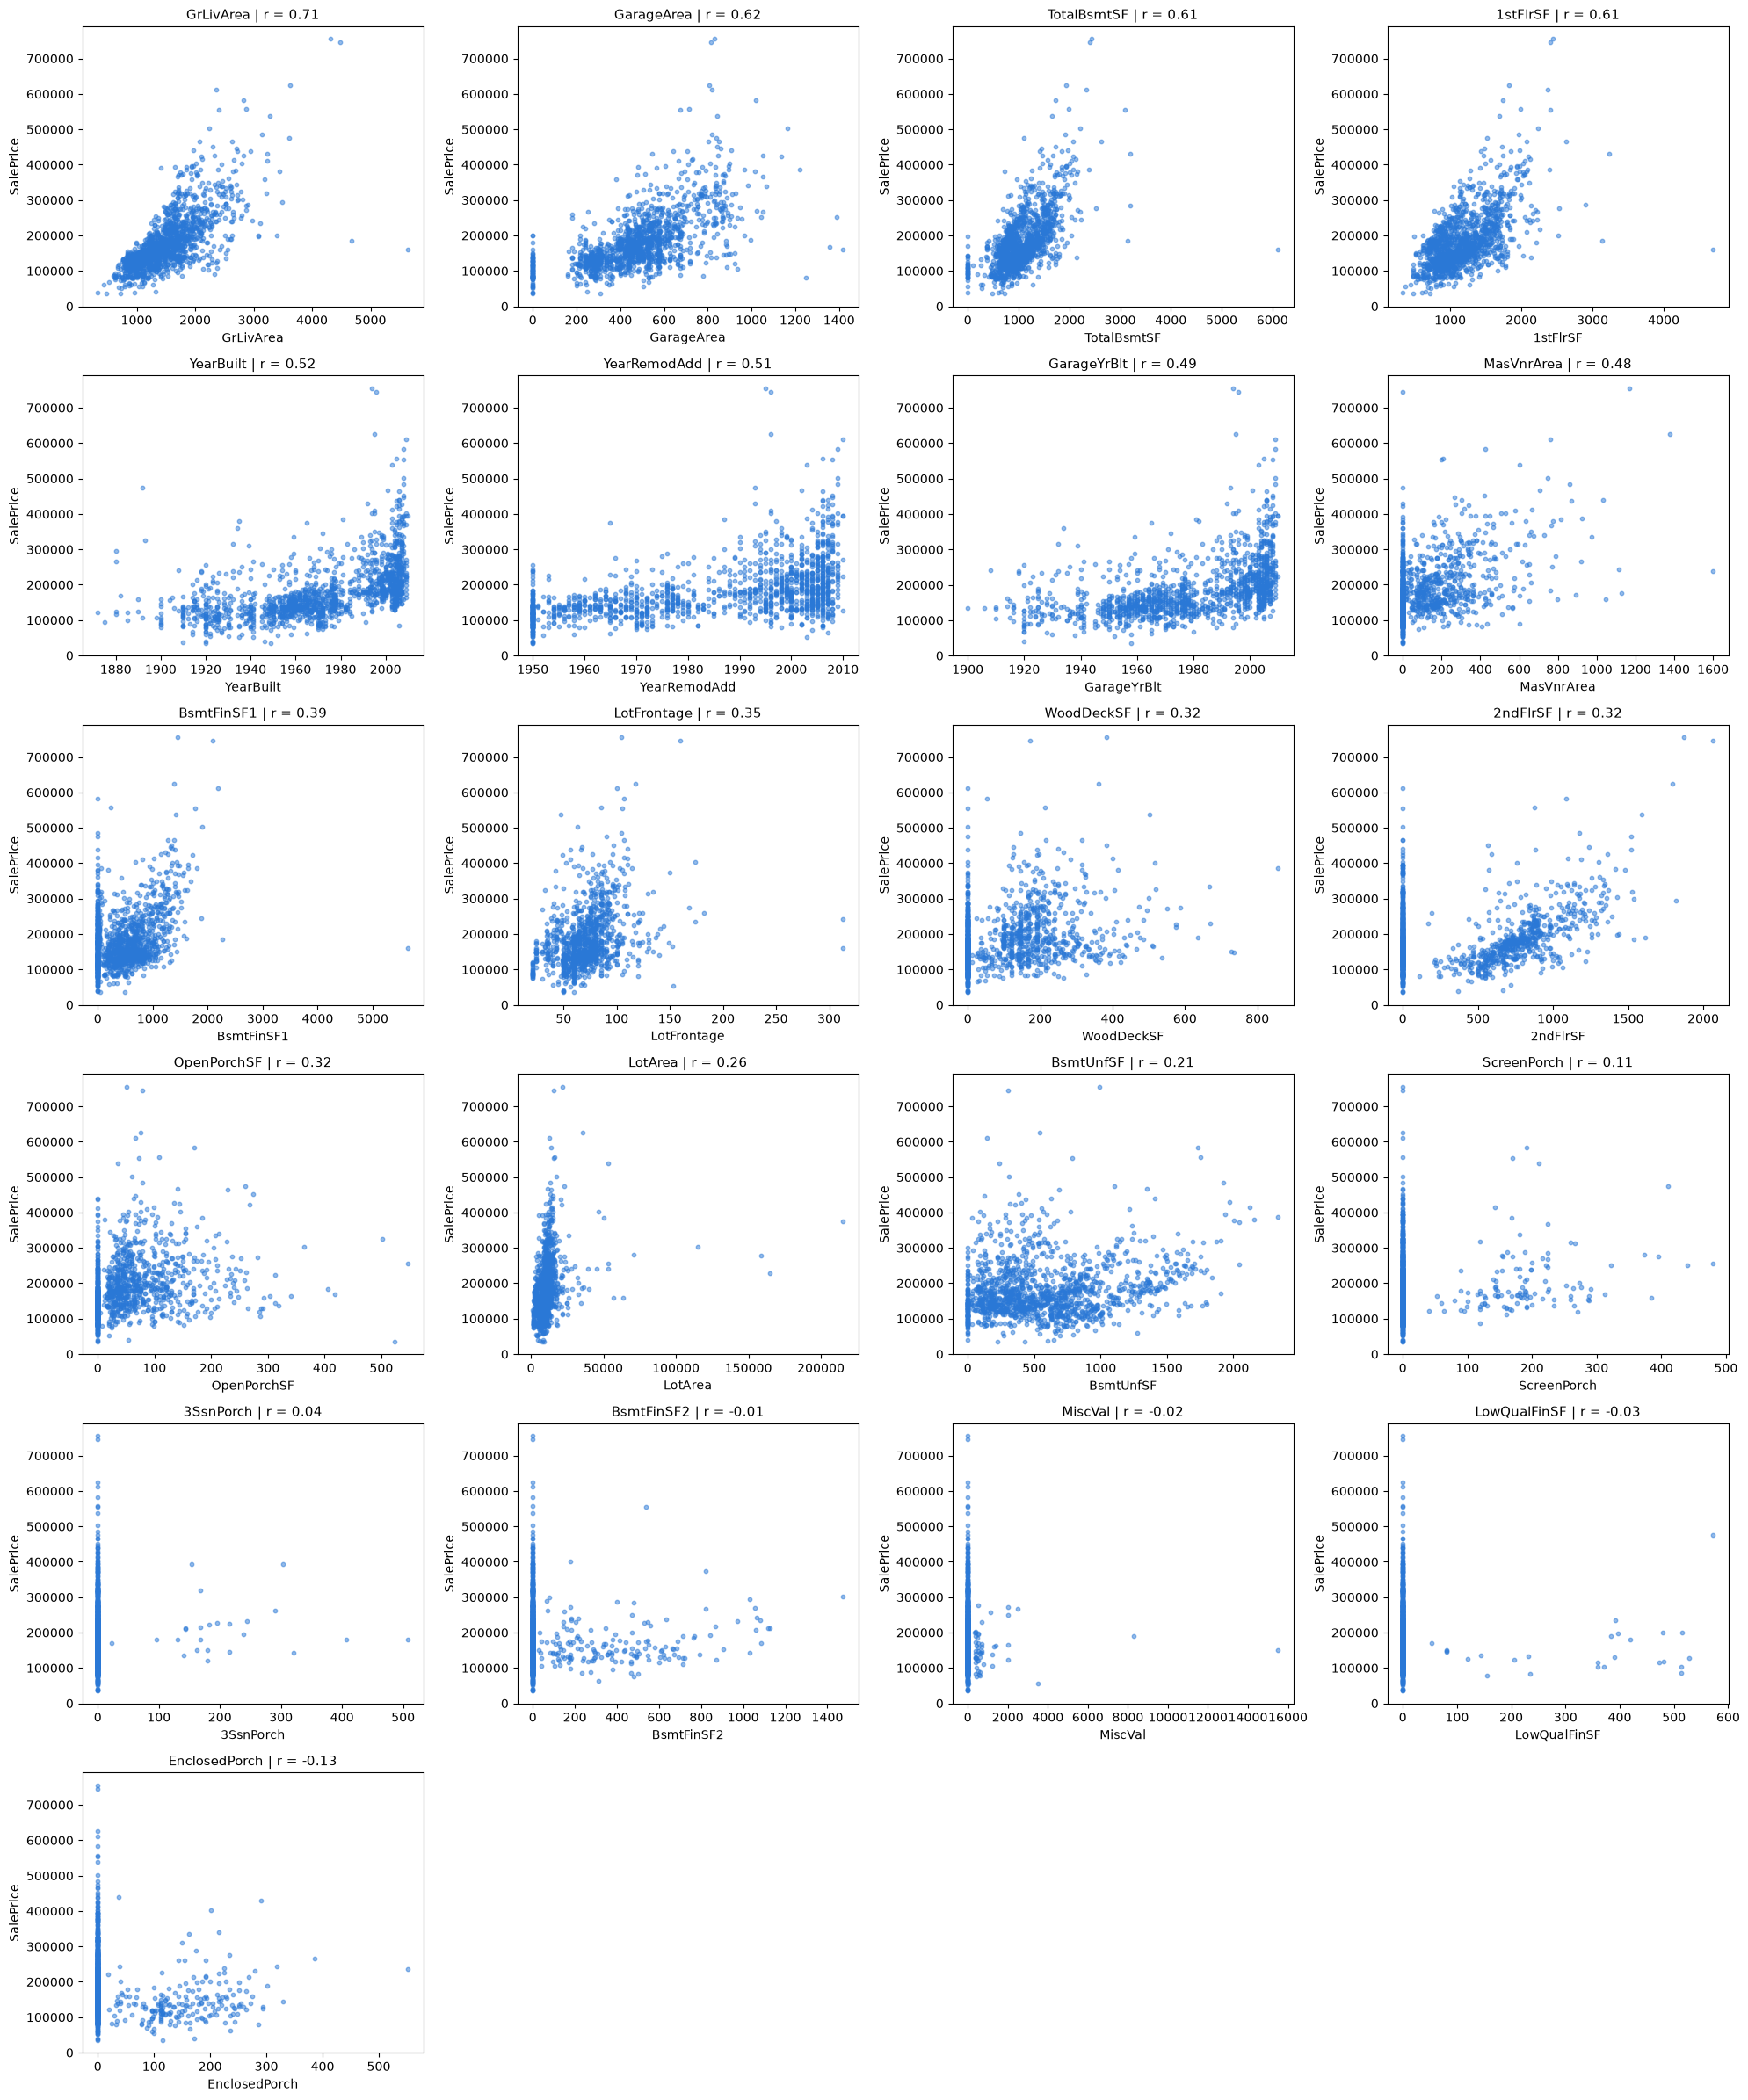

In [7]:
correlaciones = df_correlacion.set_index("variable")["correlacion"]

N_COLUMNAS = 4
n_filas = int(np.ceil(len(variables_continuas) / N_COLUMNAS))

fig, axes = plt.subplots(n_filas, N_COLUMNAS, figsize=(5 * N_COLUMNAS, 4 * n_filas))
axes = axes.flatten()

for ax, variable in zip(axes, variables_continuas):
    ax.scatter(df_train[variable], df_train[TARGET], s=10, alpha=0.5, color="#2a78d6")
    ax.set_title(f"{variable} | r = {correlaciones[variable]:.2f}", fontsize=11)
    ax.set_xlabel(variable)
    ax.set_ylabel(TARGET)

# Ocultar los ejes sobrantes de la cuadrícula
for ax in axes[len(variables_continuas):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

## 8. Diagramas de caja: variables discretas vs `SalePrice`

Se genera un diagrama de caja por cada variable discreta, con sus valores en el eje X y `SalePrice` en el eje Y. Sobre cada caja se superponen las observaciones individuales con desplazamiento horizontal aleatorio (*jitter*) para mostrar la cantidad de registros y su dispersión en cada valor.

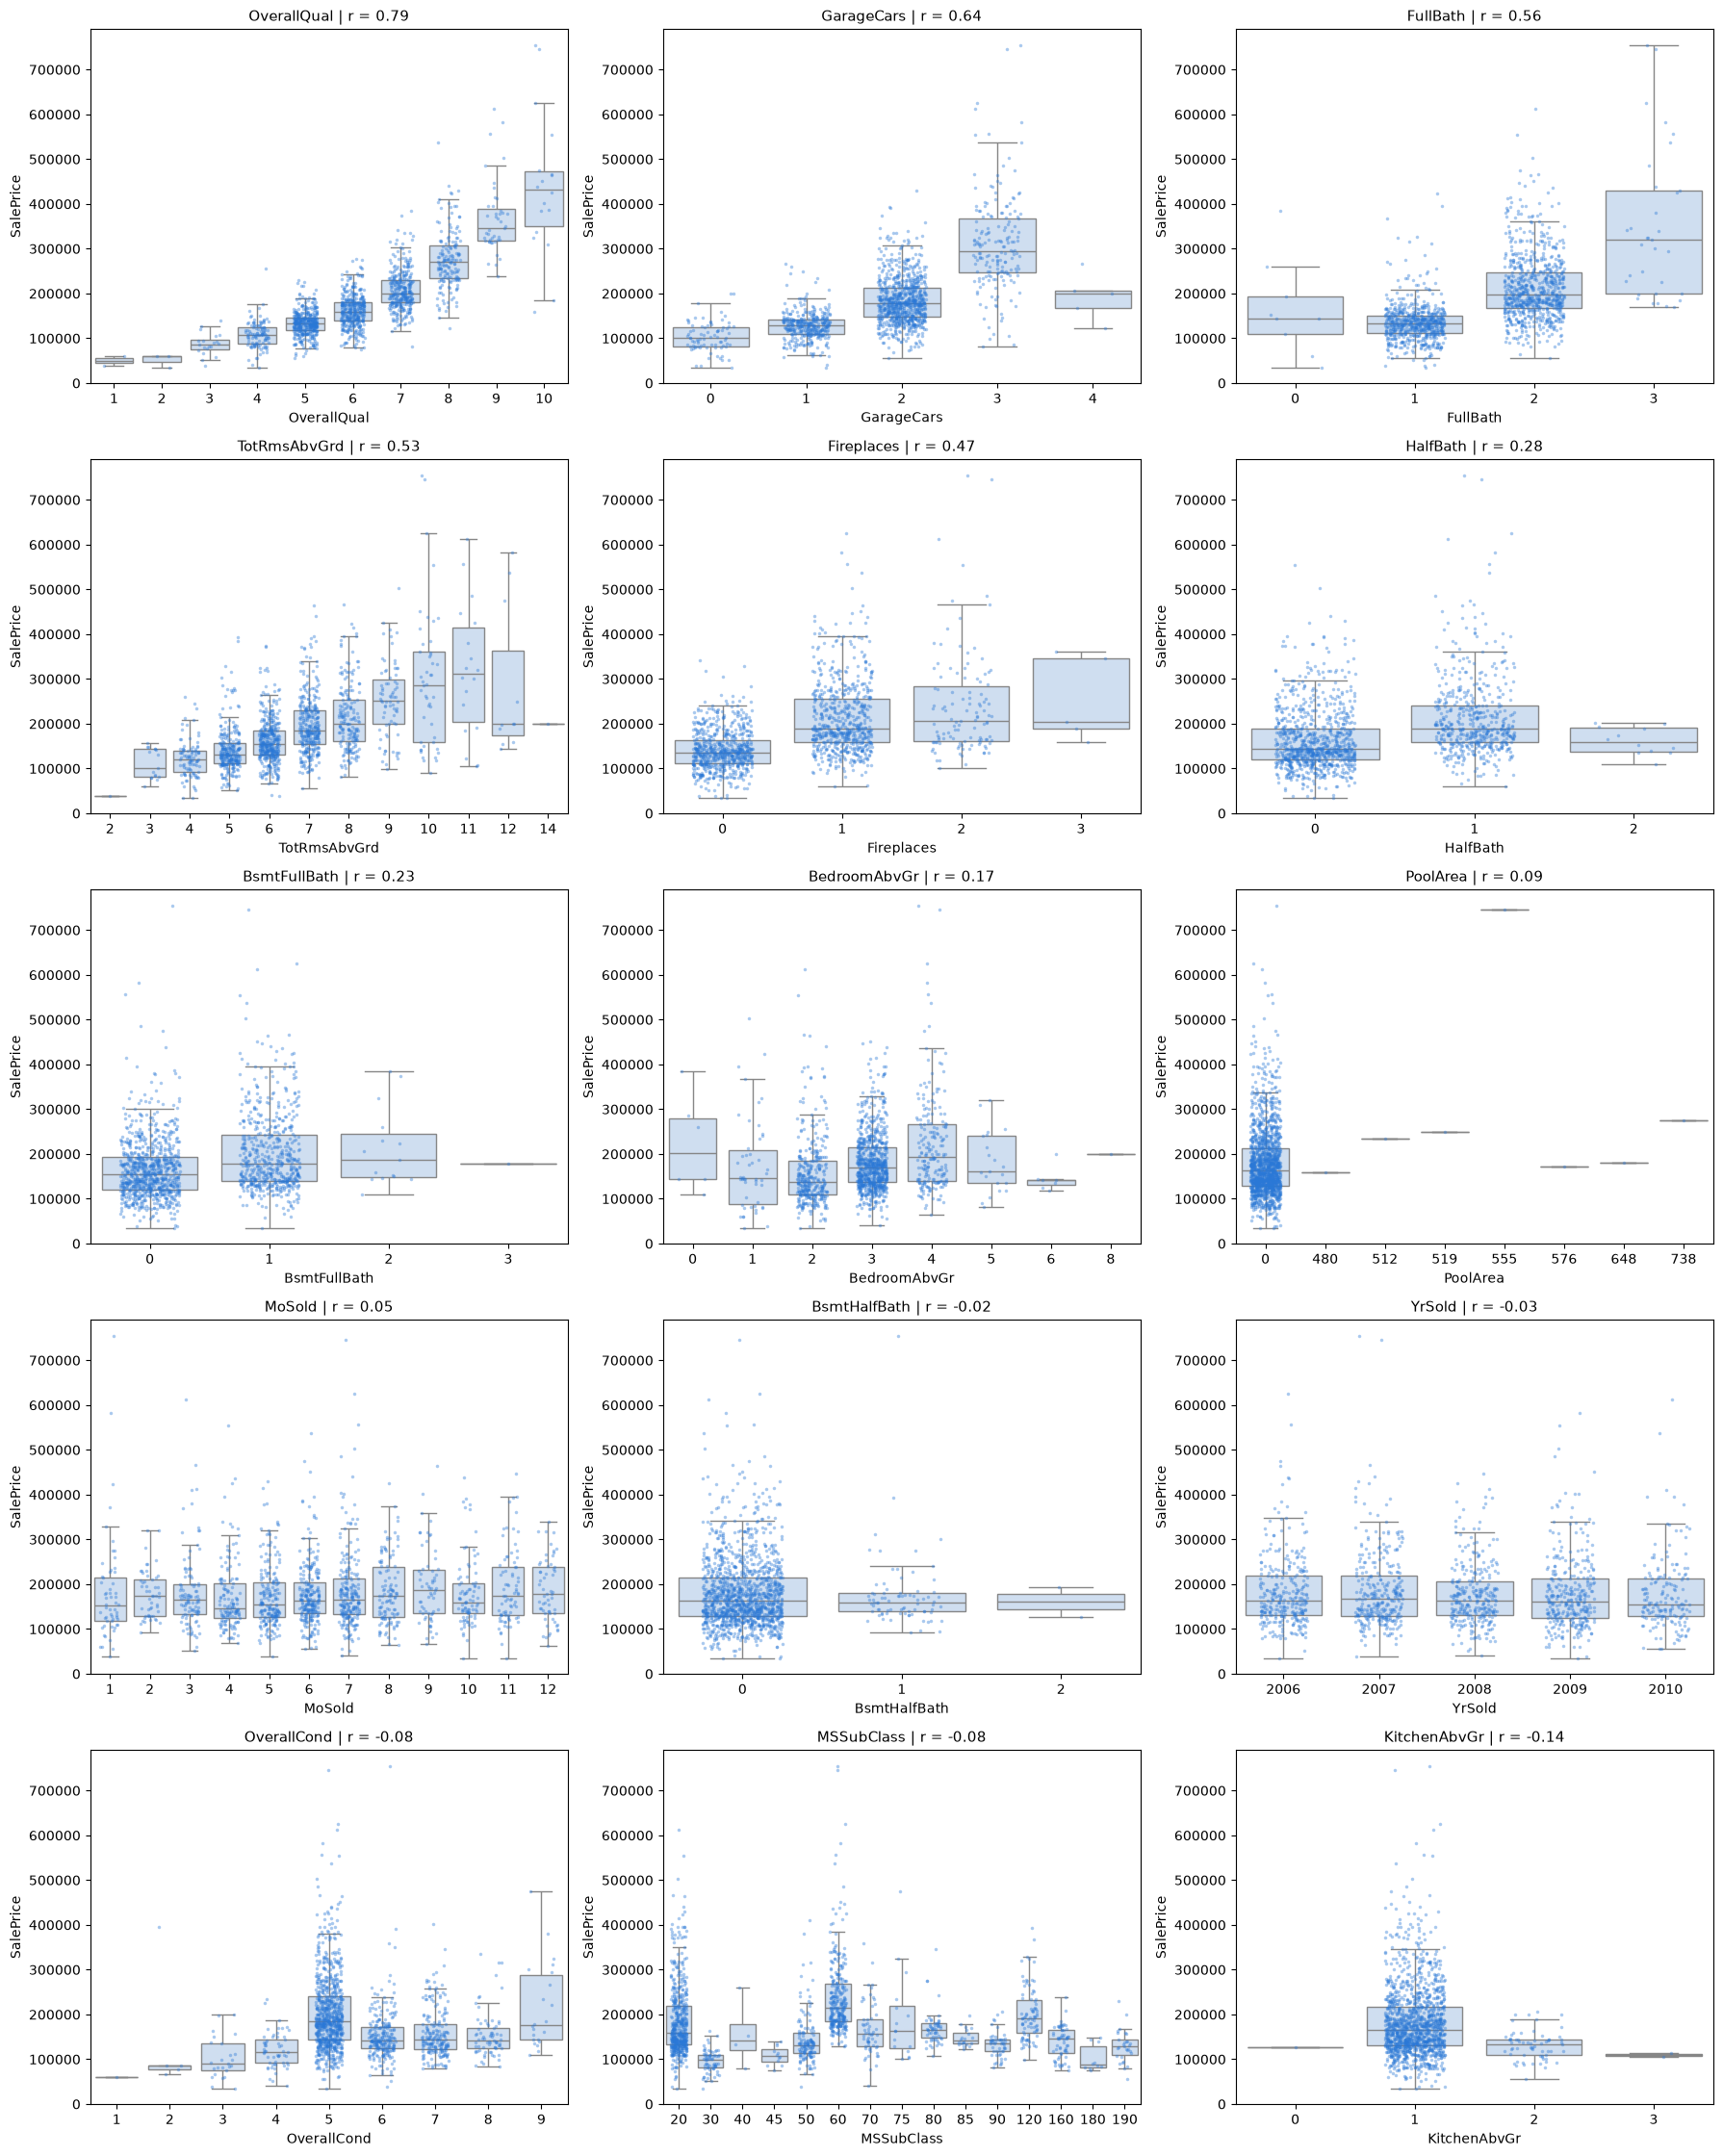

In [8]:
N_COLUMNAS = 3
n_filas = int(np.ceil(len(variables_discretas) / N_COLUMNAS))

fig, axes = plt.subplots(n_filas, N_COLUMNAS, figsize=(6 * N_COLUMNAS, 4.5 * n_filas))
axes = axes.flatten()

for ax, variable in zip(axes, variables_discretas):
    sns.boxplot(
        data=df_train, x=variable, y=TARGET, ax=ax,
        color="#c9ddf5", showfliers=False, linewidth=1,
    )
    sns.stripplot(
        data=df_train, x=variable, y=TARGET, ax=ax,
        color="#2a78d6", size=2.5, alpha=0.4, jitter=0.25,
    )
    ax.set_title(f"{variable} | r = {correlaciones[variable]:.2f}", fontsize=11)
    ax.set_xlabel(variable)
    ax.set_ylabel(TARGET)

# Ocultar los ejes sobrantes de la cuadrícula
for ax in axes[len(variables_discretas):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

## 9. Asociación de variables categóricas con `SalePrice` (razón de correlación η)

Para medir la relación entre una variable categórica y una numérica se usa la **razón de correlación η (eta)**. Mide qué proporción de la variabilidad de `SalePrice` se explica por las diferencias entre categorías:

$$\eta = \sqrt{\frac{\sum_{k} n_k (\bar{y}_k - \bar{y})^2}{\sum_{i} (y_i - \bar{y})^2}}$$

donde $\bar{y}_k$ y $n_k$ son el precio promedio y el número de registros de la categoría $k$, y $\bar{y}$ es el precio promedio general. Toma valores entre 0 (todas las categorías tienen el mismo precio promedio) y 1 (la categoría determina completamente el precio), y es comparable con el valor absoluto de la correlación de Pearson. A diferencia de esta, no indica dirección, ya que las categorías no tienen un orden.

Los valores faltantes se reemplazan por la categoría `"Sin dato"`, porque en este dataset indican ausencia de la característica (por ejemplo, sin piscina o sin callejón).

In [9]:
def razon_correlacion(categorias, valores):
    """Razón de correlación η entre una variable categórica y una numérica."""
    datos = pd.DataFrame({"categoria": categorias, "valor": valores})
    media_general = datos["valor"].mean()
    resumen = datos.groupby("categoria")["valor"].agg(["mean", "count"])

    ss_entre = (resumen["count"] * (resumen["mean"] - media_general) ** 2).sum()
    ss_total = ((datos["valor"] - media_general) ** 2).sum()
    return np.sqrt(ss_entre / ss_total)


columnas_categoricas = df_train.select_dtypes(include="str").columns.tolist()
df_categoricas = df_train[columnas_categoricas].fillna("Sin dato")

df_eta = (
    pd.DataFrame({
        "variable": columnas_categoricas,
        "eta": [razon_correlacion(df_categoricas[col], df_train[TARGET]) for col in columnas_categoricas],
        "n_categorias": [df_categoricas[col].nunique() for col in columnas_categoricas],
    })
    .sort_values("eta", ascending=False)
    .reset_index(drop=True)
)

df_eta

,variable,eta,n_categorias
0,Neighborhood,0.738630,25
1,ExterQual,0.690933,4
2,BsmtQual,0.681905,5
3,KitchenQual,0.675721,4
4,GarageFinish,0.553059,4
5,FireplaceQu,0.542181,6
6,Foundation,0.506328,6
7,GarageType,0.499204,7
8,BsmtFinType1,0.459141,7
9,HeatingQC,0.442154,5


## 10. Diagramas de caja: variables categóricas vs `SalePrice`

Se genera un diagrama de caja por cada variable categórica, en el orden de la tabla anterior, con su valor de η en el título. Las categorías se ordenan por precio mediano de menor a mayor y se superponen las observaciones individuales para mostrar cuántos registros tiene cada categoría.

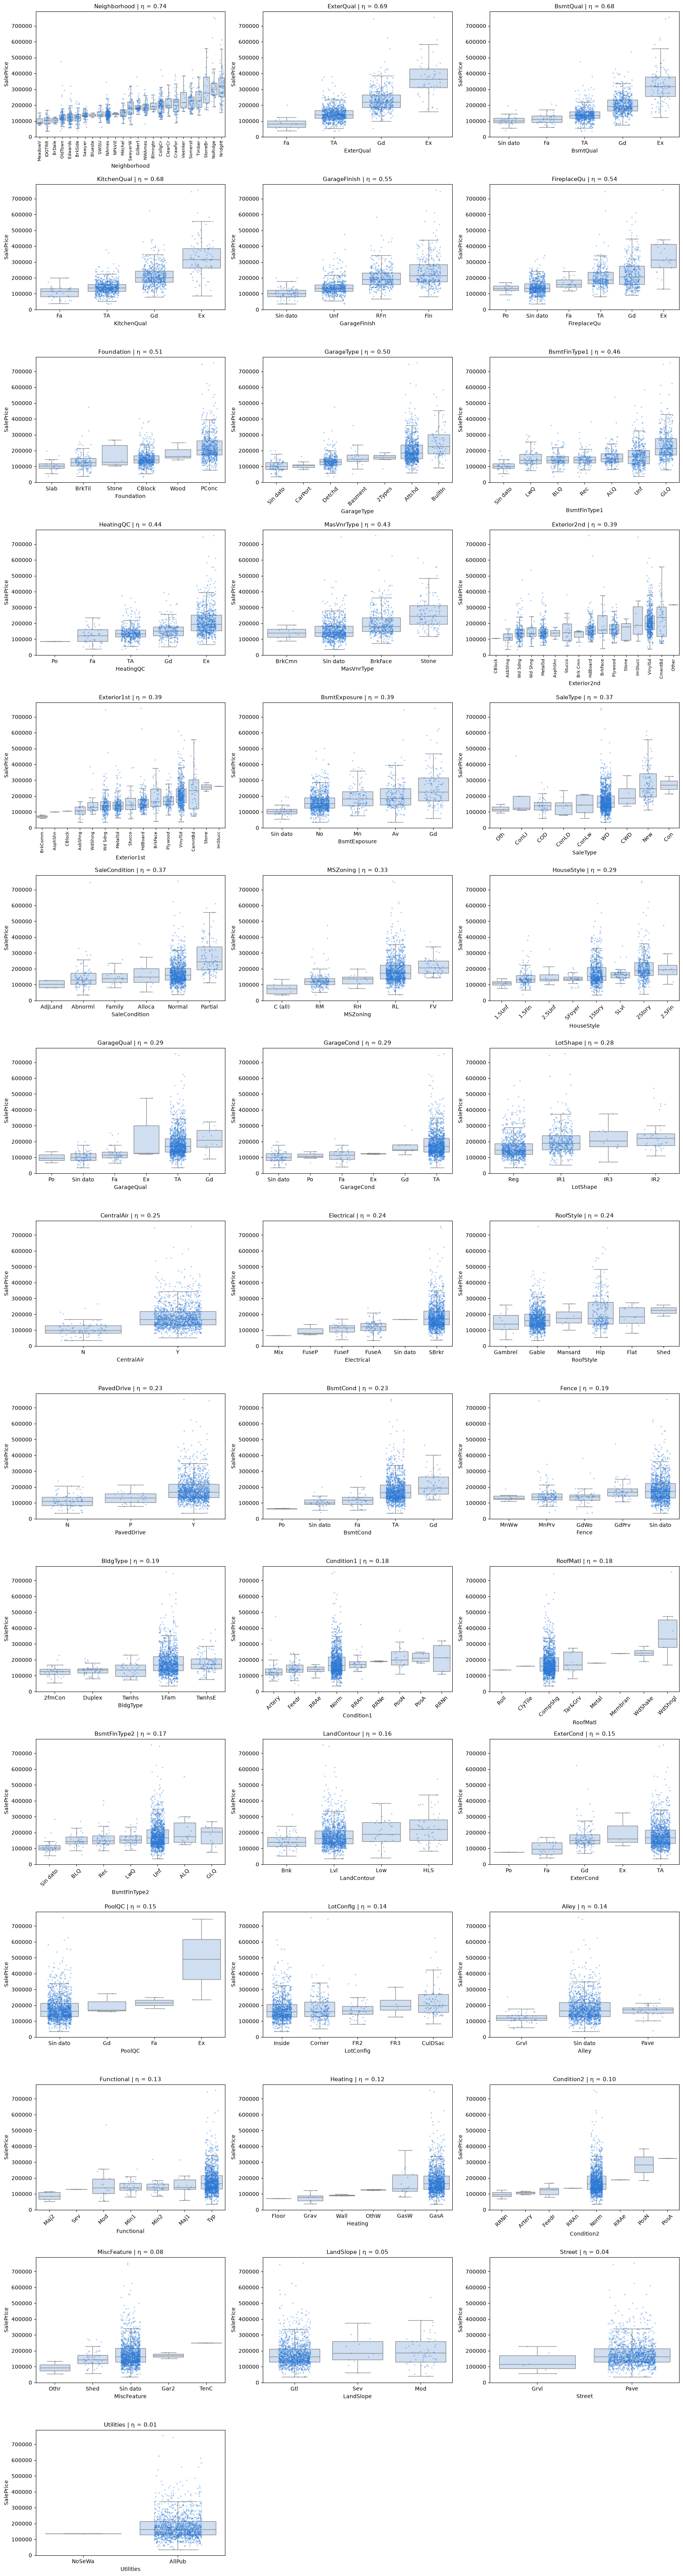

In [10]:
N_COLUMNAS = 3
n_filas = int(np.ceil(len(df_eta) / N_COLUMNAS))

fig, axes = plt.subplots(n_filas, N_COLUMNAS, figsize=(6 * N_COLUMNAS, 4.5 * n_filas))
axes = axes.flatten()

for ax, (variable, eta, n_categorias) in zip(axes, df_eta.itertuples(index=False)):
    datos = pd.DataFrame({variable: df_categoricas[variable], TARGET: df_train[TARGET]})
    orden = datos.groupby(variable)[TARGET].median().sort_values().index

    sns.boxplot(
        data=datos, x=variable, y=TARGET, order=orden, ax=ax,
        color="#c9ddf5", showfliers=False, linewidth=1,
    )
    sns.stripplot(
        data=datos, x=variable, y=TARGET, order=orden, ax=ax,
        color="#2a78d6", size=2.5, alpha=0.4, jitter=0.25,
    )
    ax.set_title(f"{variable} | η = {eta:.2f}", fontsize=11)
    ax.set_xlabel(variable)
    ax.set_ylabel(TARGET)
    if n_categorias > 10:
        ax.tick_params(axis="x", labelrotation=90, labelsize=8)
    elif n_categorias > 6:
        ax.tick_params(axis="x", labelrotation=45)

# Ocultar los ejes sobrantes de la cuadrícula
for ax in axes[len(df_eta):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

## 11. Selección de variables para el modelo

Se seleccionan las 10 variables con mayor asociación con `SalePrice` en cada grupo:

- **Continuas y discretas:** valor absoluto de la correlación de Pearson |r|, para incluir también relaciones negativas fuertes.
- **Categóricas:** razón de correlación η.

La unión de los tres grupos forma la lista `modelo_features`.

In [11]:
TOP_N = 10

abs_correlacion = correlaciones.abs()

top_continuas = abs_correlacion[variables_continuas].nlargest(TOP_N).index.tolist()
top_discretas = abs_correlacion[variables_discretas].nlargest(TOP_N).index.tolist()
top_categoricas = df_eta.nlargest(TOP_N, "eta")["variable"].tolist()

modelo_features = top_continuas + top_discretas + top_categoricas

print(f"Continuas ({len(top_continuas)}):   {top_continuas}")
print(f"Discretas ({len(top_discretas)}):   {top_discretas}")
print(f"Categóricas ({len(top_categoricas)}): {top_categoricas}")
print(f"\nTotal de features: {len(modelo_features)}")

Continuas (10):   ['GrLivArea', 'GarageArea', 'TotalBsmtSF', '1stFlrSF', 'YearBuilt', 'YearRemodAdd', 'GarageYrBlt', 'MasVnrArea', 'BsmtFinSF1', 'LotFrontage']
Discretas (10):   ['OverallQual', 'GarageCars', 'FullBath', 'TotRmsAbvGrd', 'Fireplaces', 'HalfBath', 'BsmtFullBath', 'BedroomAbvGr', 'KitchenAbvGr', 'PoolArea']
Categóricas (10): ['Neighborhood', 'ExterQual', 'BsmtQual', 'KitchenQual', 'GarageFinish', 'FireplaceQu', 'Foundation', 'GarageType', 'BsmtFinType1', 'HeatingQC']

Total de features: 30


## 12. Exportación de la configuración del pipeline

Se guarda la lista de variables seleccionadas en `pipeline_config.yaml`, en la raíz del proyecto, bajo la clave `MODEL_FEATURES`. Este archivo será la fuente de las features para las siguientes etapas (creación de features y entrenamiento).

In [12]:
import yaml
from ejercicio_clases.config import PROJ_ROOT

CONFIG_FILE = PROJ_ROOT / "pipeline_config.yaml"

with open(CONFIG_FILE, "w", encoding="utf-8") as archivo:
    yaml.safe_dump({"MODEL_FEATURES": modelo_features}, archivo, sort_keys=False, allow_unicode=True)

print(f"Configuración guardada en: {CONFIG_FILE}")

Configuración guardada en: C:\Users\aillu\OneDrive - Empresa Eléctrica de Guatemala, S.A. (EEGSA)\Mis Documentos\Universidad\4. Trimestre\1 - PRODUCT DEVELOPMENT\3. Semana\Ejercicio en Clases\ejercicio_clases\pipeline_config.yaml
